In [1]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.
import kagglehub
zadafiyabhrami_global_crocodile_species_dataset_path = kagglehub.dataset_download('zadafiyabhrami/global-crocodile-species-dataset')

print('Data source import complete.')


Using Colab cache for faster access to the 'global-crocodile-species-dataset' dataset.
Data source import complete.


# Loading DataSet

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px

In [3]:
df = pd.read_csv("/kaggle/input/global-crocodile-species-dataset/crocodile_dataset.csv")
df.head()

,Observation ID,Common Name,Scientific Name,Family,Genus,Observed Length (m),Observed Weight (kg),Age Class,Sex,Date of Observation,Country/Region,Habitat Type,Conservation Status,Observer Name,Notes
0,1,Morelet's Crocodile,Crocodylus moreletii,Crocodylidae,Crocodylus,1.90,62.0,Adult,Male,31-03-2018,Belize,Swamps,Least Concern,Allison Hill,Cause bill scientist nation opportunity.
1,2,American Crocodile,Crocodylus acutus,Crocodylidae,Crocodylus,4.09,334.5,Adult,Male,28-01-2015,Venezuela,Mangroves,Vulnerable,Brandon Hall,Ago current practice nation determine operatio...
2,3,Orinoco Crocodile,Crocodylus intermedius,Crocodylidae,Crocodylus,1.08,118.2,Juvenile,Unknown,07-12-2010,Venezuela,Flooded Savannas,Critically Endangered,Melissa Peterson,Democratic shake bill here grow gas enough ana...
3,4,Morelet's Crocodile,Crocodylus moreletii,Crocodylidae,Crocodylus,2.42,90.4,Adult,Male,01-11-2019,Mexico,Rivers,Least Concern,Edward Fuller,Officer relate animal direction eye bag do.
4,5,Mugger Crocodile (Marsh Crocodile),Crocodylus palustris,Crocodylidae,Crocodylus,3.75,269.4,Adult,Unknown,15-07-2019,India,Rivers,Vulnerable,Donald Reid,Class great prove reduce raise author play mov...


# Data Analysis

## Data Exploration

In [4]:
df.columns

Index(['Observation ID', 'Common Name', 'Scientific Name', 'Family', 'Genus',
       'Observed Length (m)', 'Observed Weight (kg)', 'Age Class', 'Sex',
       'Date of Observation', 'Country/Region', 'Habitat Type',
       'Conservation Status', 'Observer Name', 'Notes'],
      dtype='object')

In [5]:
df.isna().sum()

,0
Observation ID,0
Common Name,0
Scientific Name,0
Family,0
Genus,0
Observed Length (m),0
Observed Weight (kg),0
Age Class,0
Sex,0
Date of Observation,0


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Observation ID        1000 non-null   int64  
 1   Common Name           1000 non-null   object 
 2   Scientific Name       1000 non-null   object 
 3   Family                1000 non-null   object 
 4   Genus                 1000 non-null   object 
 5   Observed Length (m)   1000 non-null   float64
 6   Observed Weight (kg)  1000 non-null   float64
 7   Age Class             1000 non-null   object 
 8   Sex                   1000 non-null   object 
 9   Date of Observation   1000 non-null   object 
 10  Country/Region        1000 non-null   object 
 11  Habitat Type          1000 non-null   object 
 12  Conservation Status   1000 non-null   object 
 13  Observer Name         1000 non-null   object 
 14  Notes                 1000 non-null   object 
dtypes: float64(2), int64(1

In [7]:
df.describe()

,Observation ID,Observed Length (m),Observed Weight (kg)
count,1000.000000,1000.000000,1000.000000
mean,500.500000,2.415110,155.771900
std,288.819436,1.097542,175.186788
min,1.000000,0.140000,4.400000
25%,250.750000,1.637500,53.225000
50%,500.500000,2.430000,100.600000
75%,750.250000,3.010000,168.875000
max,1000.000000,6.120000,1139.700000


In [8]:
cv = df.select_dtypes(exclude="number")
for col in cv:
    print(df[col].value_counts())
    print("\n")

Common Name
New Guinea Crocodile                         68
Borneo Crocodile (disputed)                  67
American Crocodile                           66
Morelet's Crocodile                          64
Cuban Crocodile                              59
Orinoco Crocodile                            58
Philippine Crocodile                         58
Saltwater Crocodile                          58
West African Dwarf Crocodile                 57
Central African Slender-snouted Crocodile    56
West African Slender-snouted Crocodile       55
West African Crocodile                       52
Hall's New Guinea Crocodile                  49
Congo Dwarf Crocodile                        48
Nile Crocodile                               48
Mugger Crocodile (Marsh Crocodile)           47
Siamese Crocodile                            45
Freshwater Crocodile (Johnstone's)           45
Name: count, dtype: int64


Scientific Name
Crocodylus novaeguineae    68
Crocodylus raninus         67
Crocodylus acutus   

## Locating Species

In [9]:
con_gr = df.groupby(["Common Name", "Scientific Name", "Genus"])["Country/Region"].apply(set).reset_index()
con_gr["Country/Region"] = con_gr["Country/Region"].apply(lambda x: list(x))
con_gr

,Common Name,Scientific Name,Genus,Country/Region
0,American Crocodile,Crocodylus acutus,Crocodylus,"[Colombia, Mexico, Costa Rica, Cuba, USA (Flor..."
1,Borneo Crocodile (disputed),Crocodylus raninus,Crocodylus,"[Malaysia (Borneo), Indonesia (Borneo)]"
2,Central African Slender-snouted Crocodile,Mecistops leptorhynchus,Mecistops,"[Congo Basin Countries, Cameroon, Gabon]"
3,Congo Dwarf Crocodile,Osteolaemus osborni,Osteolaemus,"[Congo (DRC), Central African Republic]"
4,Cuban Crocodile,Crocodylus rhombifer,Crocodylus,[Cuba]
5,Freshwater Crocodile (Johnstone's),Crocodylus johnstoni,Crocodylus,[Australia]
6,Hall's New Guinea Crocodile,Crocodylus halli,Crocodylus,[Papua New Guinea]
7,Morelet's Crocodile,Crocodylus moreletii,Crocodylus,"[Guatemala, Belize, Mexico]"
8,Mugger Crocodile (Marsh Crocodile),Crocodylus palustris,Crocodylus,"[Iran (historic), Pakistan, Nepal, Sri Lanka, ..."
9,New Guinea Crocodile,Crocodylus novaeguineae,Crocodylus,"[Indonesia (Papua), Papua New Guinea]"


## Species length classification

In [10]:
len_gr = df.groupby(["Common Name", "Scientific Name", "Genus"])["Observed Length (m)"].max().reset_index()
len_gr = len_gr.sort_values(by="Observed Length (m)", ascending=False)
len_gr

,Common Name,Scientific Name,Genus,Observed Length (m)
13,Saltwater Crocodile,Crocodylus porosus,Crocodylus,6.12
10,Nile Crocodile,Crocodylus niloticus,Crocodylus,5.31
11,Orinoco Crocodile,Crocodylus intermedius,Crocodylus,4.81
0,American Crocodile,Crocodylus acutus,Crocodylus,4.33
8,Mugger Crocodile (Marsh Crocodile),Crocodylus palustris,Crocodylus,4.03
1,Borneo Crocodile (disputed),Crocodylus raninus,Crocodylus,3.91
6,Hall's New Guinea Crocodile,Crocodylus halli,Crocodylus,3.49
17,West African Slender-snouted Crocodile,Mecistops cataphractus,Mecistops,3.41
7,Morelet's Crocodile,Crocodylus moreletii,Crocodylus,3.40
4,Cuban Crocodile,Crocodylus rhombifer,Crocodylus,3.38


## Species weight classification

In [11]:
we_gr = df.groupby(["Common Name", "Scientific Name", "Genus"])["Observed Weight (kg)"].max().reset_index()
we_gr = we_gr.sort_values(by="Observed Weight (kg)", ascending=False)
we_gr

,Common Name,Scientific Name,Genus,Observed Weight (kg)
13,Saltwater Crocodile,Crocodylus porosus,Crocodylus,1139.7
10,Nile Crocodile,Crocodylus niloticus,Crocodylus,998.3
11,Orinoco Crocodile,Crocodylus intermedius,Crocodylus,718.2
0,American Crocodile,Crocodylus acutus,Crocodylus,418.1
8,Mugger Crocodile (Marsh Crocodile),Crocodylus palustris,Crocodylus,292.8
1,Borneo Crocodile (disputed),Crocodylus raninus,Crocodylus,273.7
17,West African Slender-snouted Crocodile,Mecistops cataphractus,Mecistops,230.9
4,Cuban Crocodile,Crocodylus rhombifer,Crocodylus,203.8
15,West African Crocodile,Crocodylus suchus,Crocodylus,201.2
6,Hall's New Guinea Crocodile,Crocodylus halli,Crocodylus,198.2


# Data Visualization

## Crocodile length vs. weight by Species

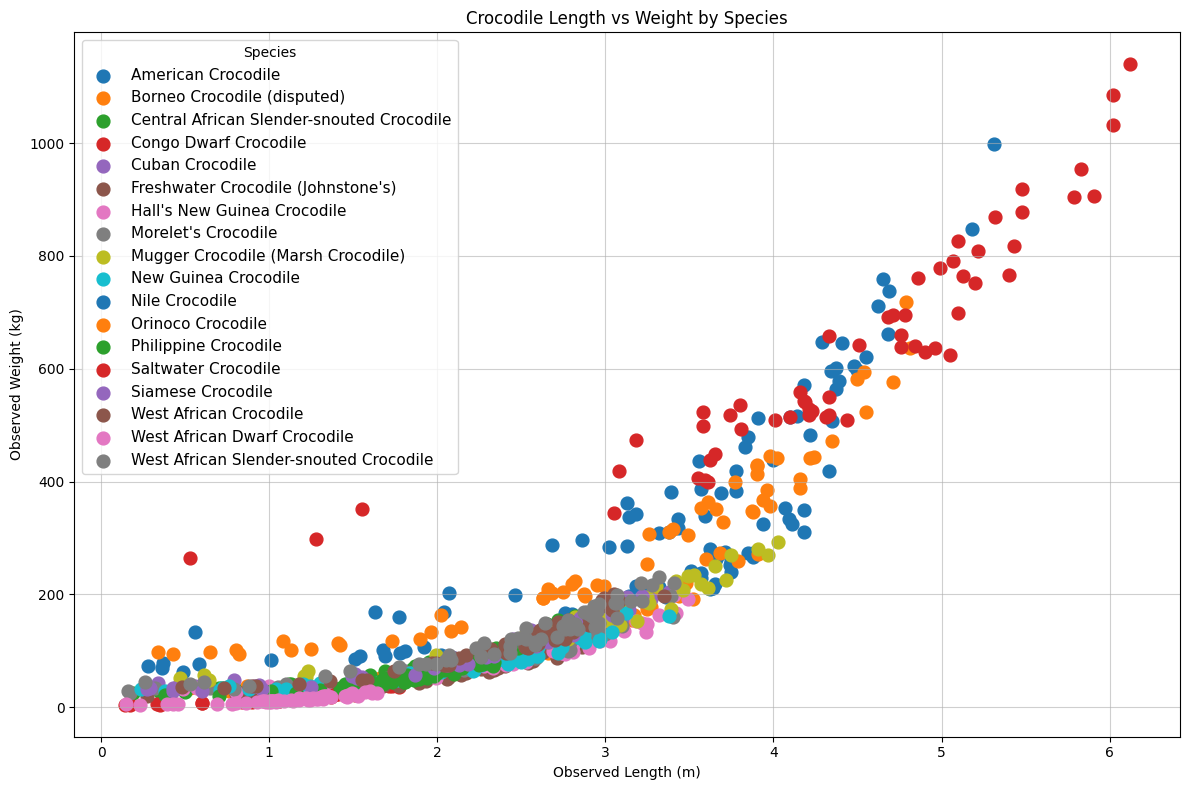

In [12]:
plt.figure(figsize=(12, 8))
for species, sub in df.groupby('Common Name'):
    plt.scatter(sub['Observed Length (m)'], sub['Observed Weight (kg)'], label=species, s=85)
plt.xlabel('Observed Length (m)')
plt.ylabel('Observed Weight (kg)')
plt.title("Crocodile Length vs Weight by Species")
plt.grid(True, linestyle='-', alpha=0.6)
plt.legend(title='Species', fontsize=11)
plt.tight_layout()
plt.show()

## Crocodile length vs. weight by Genus

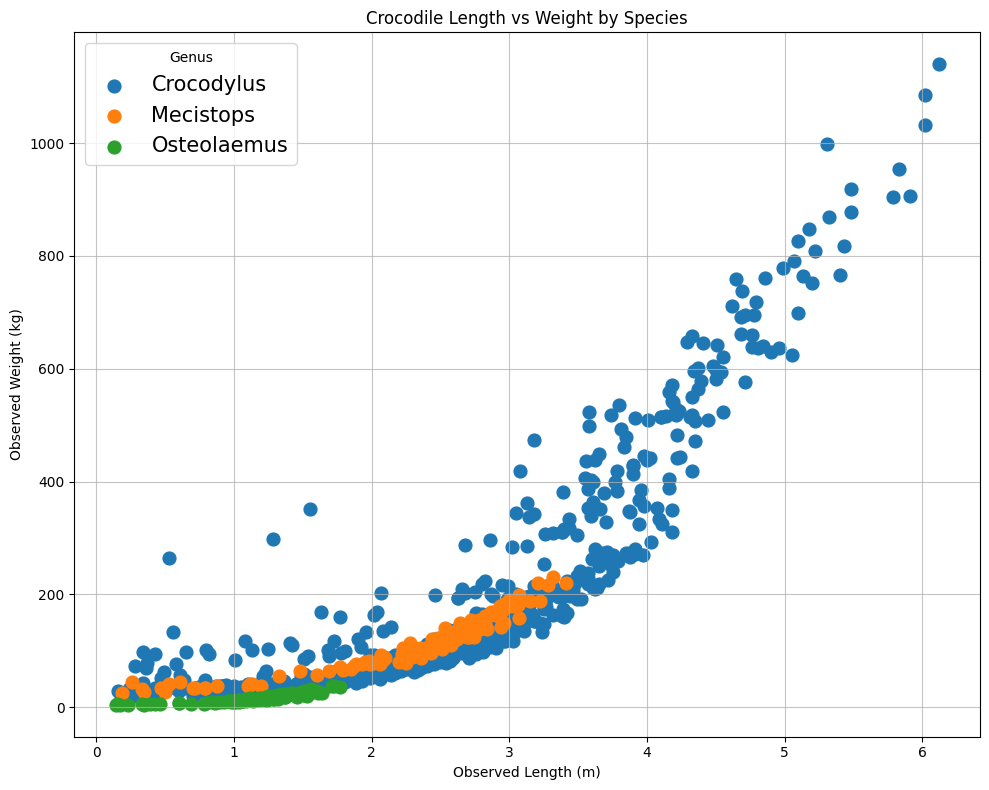

In [13]:
plt.figure(figsize=(10, 8))
for species, sub in df.groupby('Genus'):
    plt.scatter(sub['Observed Length (m)'], sub['Observed Weight (kg)'], label=species, s=85)
plt.xlabel('Observed Length (m)')
plt.ylabel('Observed Weight (kg)')
plt.title("Crocodile Length vs Weight by Species")
plt.grid(True, linestyle='-', alpha=0.75)
plt.legend(title='Genus', fontsize=15)
plt.tight_layout()
plt.show()

## Crocodile length vs. weight by Habitat Type

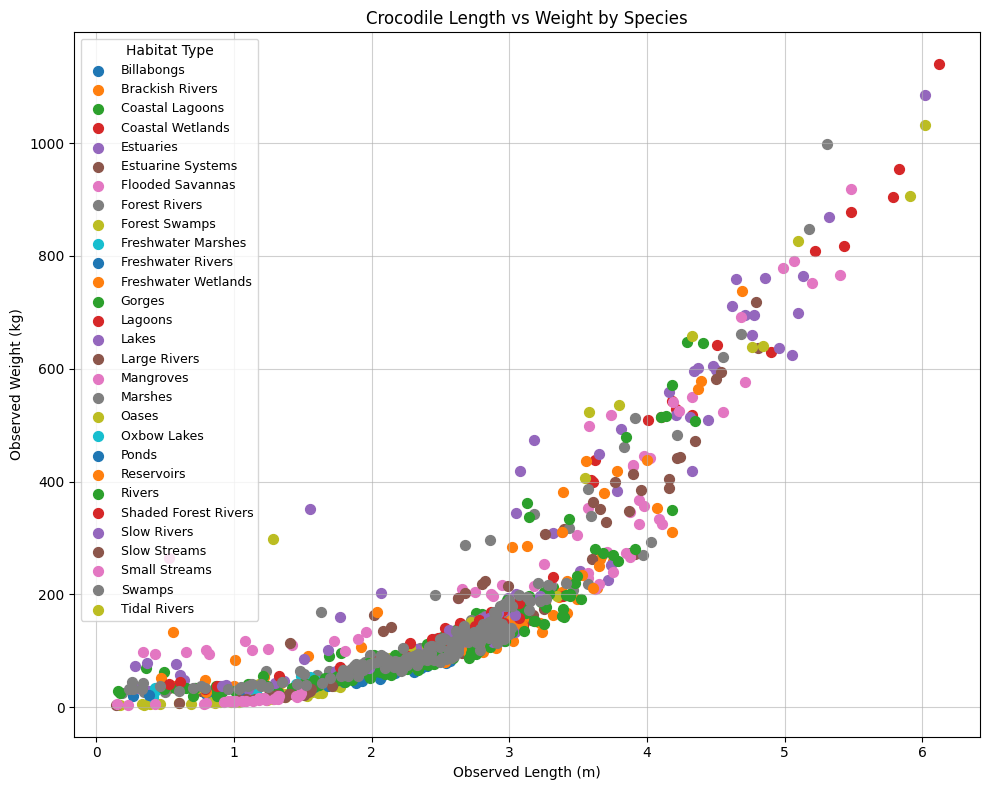

In [14]:
plt.figure(figsize=(10, 8))
for species, sub in df.groupby('Habitat Type'):
    plt.scatter(sub['Observed Length (m)'], sub['Observed Weight (kg)'], label=species, s=50)
plt.xlabel('Observed Length (m)')
plt.ylabel('Observed Weight (kg)')
plt.title("Crocodile Length vs Weight by Species")
plt.grid(True, linestyle='-', alpha=0.6)
plt.legend(title='Habitat Type', fontsize=9)
plt.tight_layout()
plt.show()

## Crocodile length vs. weight by Conservation Status

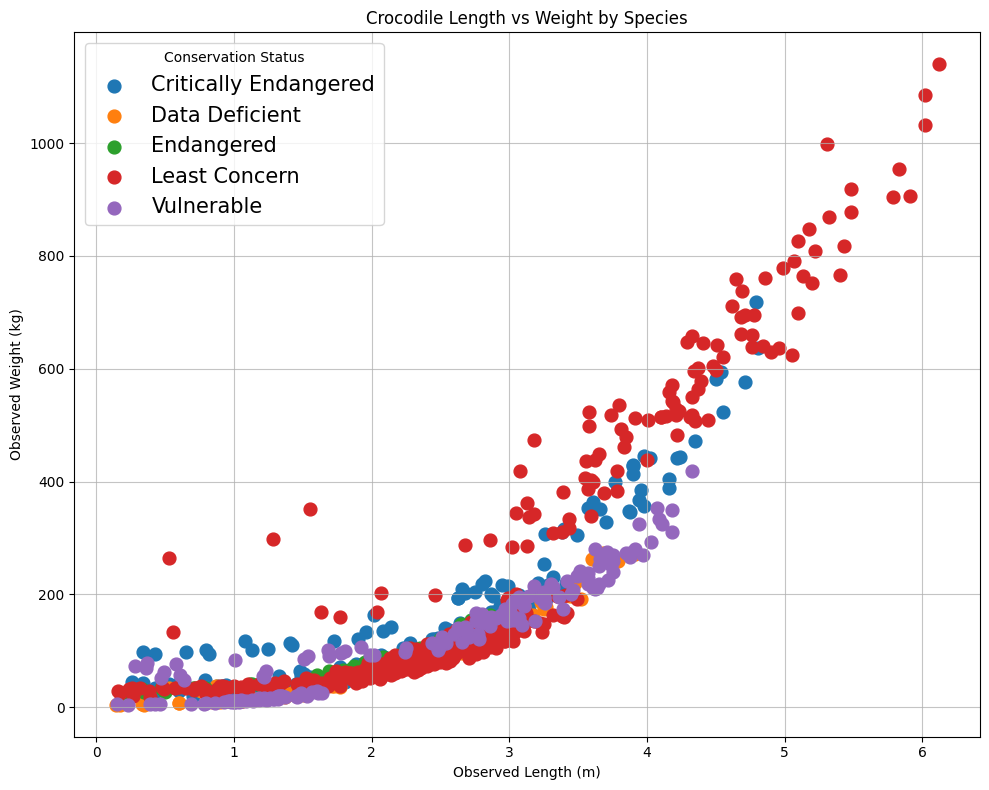

In [15]:
plt.figure(figsize=(10, 8))
for species, sub in df.groupby('Conservation Status'):
    plt.scatter(sub['Observed Length (m)'], sub['Observed Weight (kg)'], label=species, s=85)
plt.xlabel('Observed Length (m)')
plt.ylabel('Observed Weight (kg)')
plt.title("Crocodile Length vs Weight by Species")
plt.grid(True, linestyle='-', alpha=0.75)
plt.legend(title='Conservation Status', fontsize=15)
plt.tight_layout()
plt.show()

## Crocodile Distribution Map by Genus

In [16]:


fig = px.choropleth(
    df,
    locations="Country/Region",
    locationmode="country names",
    color="Genus",
    color_continuous_scale="Viridis",
    title="Crocodile Distributoin Map"
)
fig.show()

## Crocodile Distribution Map by Length

In [17]:
fig = px.choropleth(
    df,
    locations="Country/Region",
    locationmode="country names",
    color="Observed Length (m)",
    color_continuous_scale="Viridis",
    title="Crocodile Distributoin Map"
)
fig.show()

## Crocodile Distribution Map by Weight

In [18]:
fig = px.choropleth(
    df,
    locations="Country/Region",
    locationmode="country names",
    color="Observed Weight (kg)",
    color_continuous_scale="Viridis",
    title="Crocodile Distributoin Map"
)

fig.show()

## Conservation Status Observations

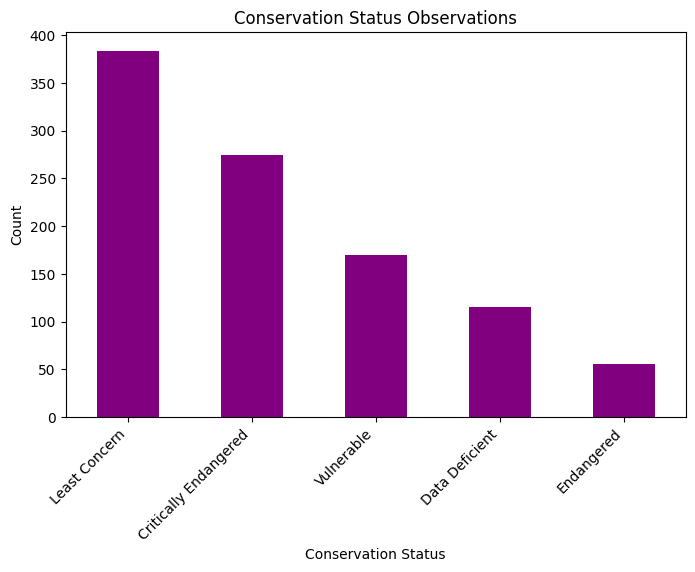

In [29]:
plt.figure(figsize=(8, 5))
stat_count = df['Conservation Status'].value_counts()
stat_count.plot(kind='bar', color='purple')
plt.title('Conservation Status Observations')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.show()

## Habitat Type prevalence

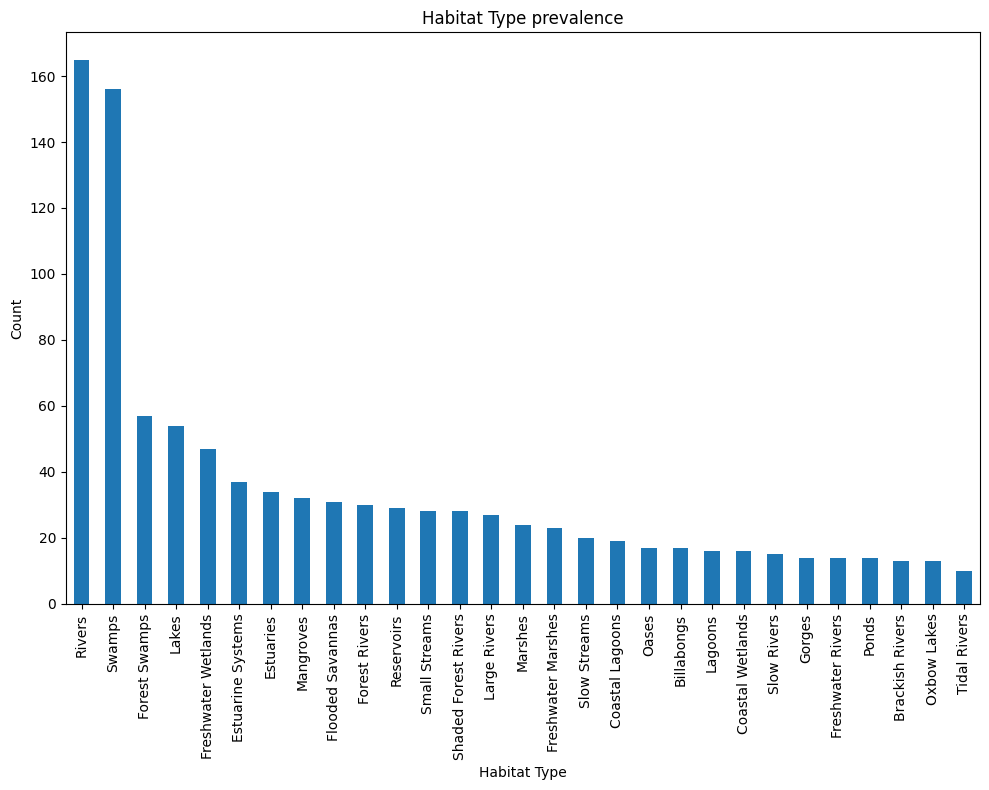

In [37]:
plt.figure(figsize=(10, 8))
hab_count = df['Habitat Type'].value_counts()
hab_count.plot(kind='bar')
plt.title('Habitat Type prevalence')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

## Timeline of observations by year

In [39]:
df['Date of Observation'] = pd.to_datetime(df['Date of Observation'], dayfirst=True, errors='coerce')
df['Year'] = df['Date of Observation'].dt.year

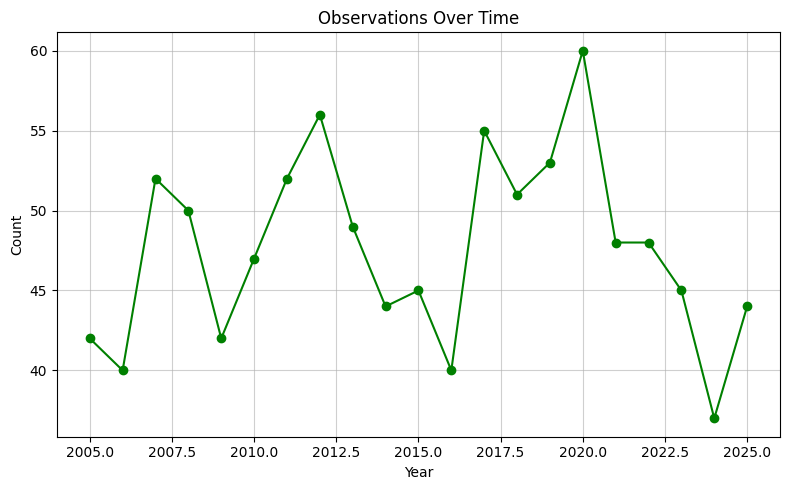

In [43]:
plt.figure(figsize=(8, 5))
years = df.groupby('Year').size().sort_index()
years.plot(kind='line', marker='o', color='green')
plt.title('Observations Over Time')
plt.xlabel('Year')
plt.ylabel('Count')
plt.grid(True, linestyle='-', alpha=0.6)
plt.tight_layout()
plt.show()

## Timeline of observations of Genus (by year)

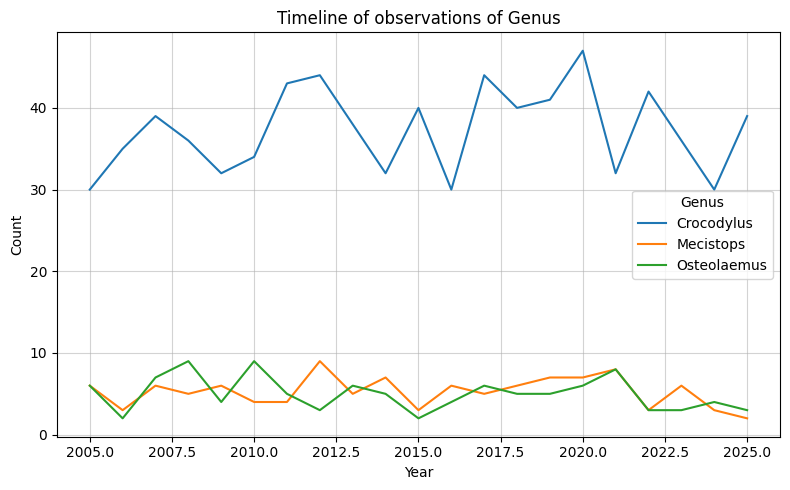

In [44]:
plt.figure(figsize=(8, 5))
gr = df.groupby(["Year", "Genus"])["Observation ID"].count().reset_index()
gr.columns = ["Year", "Genus", "Count"]
for genus, sub in gr.groupby('Genus'):
    plt.plot(sub['Year'], sub['Count'], label=genus)
plt.title('Timeline of observations of Genus')
plt.xlabel('Year')
plt.ylabel('Count')
plt.legend(title="Genus")
plt.grid(True, linestyle='-', alpha=0.55)
plt.tight_layout()
plt.show()